In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, choice_intensities=4, use_prefactor=True)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
mae_d = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                   learning_rates=0.1, discount_factors=0.9,
                   choice_intensities=4, Rmin=-10, Rmax=10,
                   method='weights', wU=1, use_prefactor=False)

In [ ]:
mae_e = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                   learning_rates=0.05, discount_factors=0.8, 
                   choice_intensities=150, Rmin=0, Rmax=10,
                   method='mean', tau=0.5, use_prefactor=True)

In [ ]:
x = ([0], [0, 1], [0])
res = np.linspace(0, 1., 11)

array([<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>,
       <Axes: title={'center': 'state 1'}, xlabel='step'>], dtype=object)

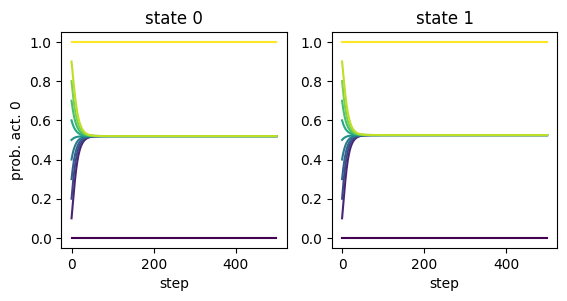

In [ ]:
trajectories_1D(mae, x, res, NrRandom=8)

array([<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>,
       <Axes: title={'center': 'state 1'}, xlabel='step'>], dtype=object)

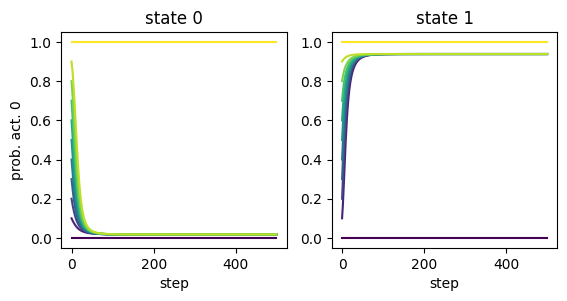

In [ ]:
trajectories_1D(mae_e, x, res, NrRandom=8)

array([<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>,
       <Axes: title={'center': 'state 1'}, xlabel='step'>], dtype=object)

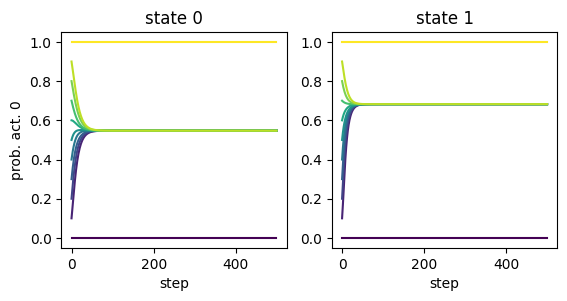

In [ ]:
trajectories_1D(mae_d, x, res, NrRandom=8)

In [ ]:
res = np.linspace(0, 1., 41)
res[0] = 0.0001
res[-1] = 0.9999

array([<Axes: title={'center': 'state 0'}, xlabel='prob. act. 0', ylabel='RPE'>,
       <Axes: title={'center': 'state 1'}, xlabel='prob. act. 0'>],
      dtype=object)

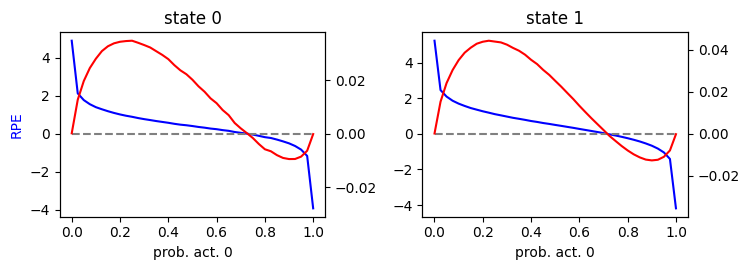

In [ ]:
phaseplot(mae, x, res, NrRandom=16)

In [ ]:
w_pes = np.linspace(0.1, 1., 10)
w_opt = np.linspace(1., 10., 10)
w_ratios = np.zeros((19))
w_ratios[:9] = w_pes[:9]
w_ratios[9:] = w_opt

In [ ]:
w_ratios

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  2. ,
        3. ,  4. ,  5. ,  6. ,  7. ,  8. ,  9. , 10. ])

In [ ]:
w_xinf = np.zeros((2, len(w_ratios)))

In [ ]:
for i, w in enumerate(w_ratios):
    mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0.9,
                     choice_intensities=4, Rmin=-1, Rmax=2,
                     method='weights', wU=w, use_prefactor=True)
    # print(w)
    X = 0.5 * np.ones((1, 2, 2))
    traj, fpreached = mae.trajectory(X, 300)
    # print(traj[-1, 0, 0, 0])
    w_xinf[0, i] = traj[-1, 0, 0, 0]
    w_xinf[1, i] = traj[-1, 0, 1, 0]
    print('done')

done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done


In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, choice_intensities=4., use_prefactor=True)
X = 0.5 * np.ones((1, 2, 2))
traj, fpreached = mae.trajectory(X, 300)
finXp = traj[-1, 0, 0, 0]
finXd = traj[-1, 0, 1, 0]

Text(0.5, 1.0, 'degraded state')

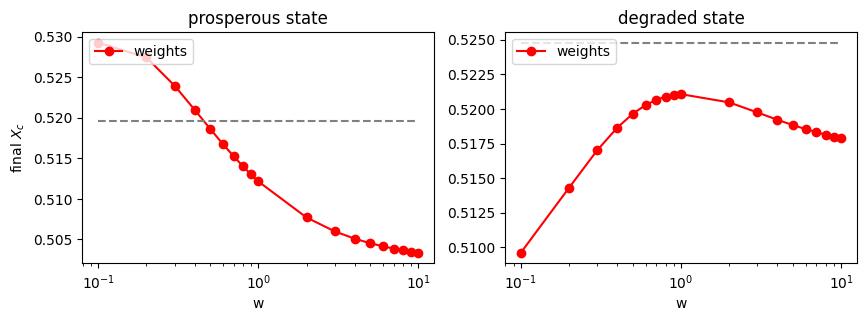

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    ax.set_xscale('log')
    ax.plot(w_ratios, w_xinf[i, :], '-o', color='red', label="weights")
    ax.legend(loc='upper left')
    ax.set_xlabel("w")
ax1.plot(w_ratios, np.repeat(finXp, len(w_ratios)), '--', color="gray")
ax2.plot(w_ratios, np.repeat(finXd, len(w_ratios)), '--', color="gray")
ax1.set_ylabel("final "+r'$X_{c}$')
ax1.set_title("prosperous state")
ax2.set_title("degraded state")

In [ ]:
w_xinf

array([[0.5270822 , 0.5270822 , 0.5270822 , 0.5270822 , 0.5270822 ,
        0.5270822 , 0.5270822 , 0.5270822 , 0.5270822 , 0.5270822 ,
        0.5270822 , 0.5270822 , 0.5270822 , 0.52708238, 0.5270822 ,
        0.5270822 , 0.5270822 , 0.52708226, 0.52708238],
       [0.52987921, 0.52987921, 0.52987927, 0.52987921, 0.52987927,
        0.52987927, 0.52987921, 0.52987921, 0.52987921, 0.52987927,
        0.52987927, 0.52987921, 0.52987927, 0.52987933, 0.52987921,
        0.52987921, 0.52987927, 0.52987927, 0.52987933]])